In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


float_list = ["Durée moyenne du trajet", "Retard moyen des trains en retard au départ", "Retard moyen des trains en retard à l'arrivée","Retard moyen trains en retard > 15 (si liaison concurrencée par vol)","Retard moyen de tous les trains à l'arrivée",
"Retard moyen de tous les trains au départ","Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic","Prct retard pour cause matériel roulant",
"Prct retard pour cause gestion en gare et réutilisation de matériel","Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

int_list = ["Nombre de circulations prévues","Nombre de trains annulés","Nombre de trains en retard à l'arrivée","Nombre de trains en retard au départ","Nombre trains en retard > 30min","Nombre trains en retard > 60min","Nombre trains en retard > 15min"]

check_if_zero = ["Durée moyenne du trajet","Nombre de circulations prévues"]

ignore_zero_columns = ["Nombre de trains annulés", "Nombre de trains en retard à l'arrivée", 
                       "Nombre de trains en retard au départ", "Nombre trains en retard > 30min",
                       "Nombre trains en retard > 60min", "Nombre trains en retard > 15min",
                       "Prct retard pour causes externes","Prct retard pour cause infrastructure","Prct retard pour cause gestion trafic",
                       "Prct retard pour cause matériel roulant","Prct retard pour cause gestion en gare et réutilisation de matériel",
                       "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"]

# create dataframe and clear row and duplicate row
data = pd.read_csv('project_dataset.csv', on_bad_lines='warn', sep=';')
data.drop(['Commentaire annulations','Commentaire retards au départ',"Commentaire retards à l'arrivée"],axis=1,inplace=True)
data = data.replace(
    ['', ' ', 'NC', 'Non communiqué', 'N/A', '-', 'None', 'NONE', 'nan', 'NaN'],
    np.nan
)




# Strips the strings, replaces spaces and / to -, and formats to year-month-days dates.
data['Date'] = data['Date'].str.strip().str.replace(' ',"-").str.replace('/','-')
data['Date'] = pd.to_datetime(data['Date'], format='mixed')

# Creates year and month dataframes.
YearDf = data['Date'].dt.year
monthDf = data['Date'].dt.month

## change value if case is empty
for element in data:
    if element in float_list or element in int_list:
        data[element] = data[element].astype(str).replace(['', 'NC', 'Non communiqué', 'N/A','-',' '], np.nan)
    else:
        data[element] = data[element].replace('', np.nan)
        data[element] = data[element].replace('NC', np.nan)
        data[element] = data[element].replace('Non communiqué', np.nan)
        data[element] = data[element].replace('N/A', np.nan)
        data[element] = data[element].replace('-', np.nan)

# format line to dataframe
for element in data:
    if element in float_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip().astype(float).round(2)
    elif element in int_list:
        data[element] = data[element].astype(str).str.replace('min', '').str.replace(',', '.').str.replace('"', '').str.replace('%', '').str.replace('-', '').str.strip()
        data[element] = pd.to_numeric(data[element], errors='coerce').fillna(0).astype(int)
    elif element == "Gare de départ" or element == "Gare d'arrivée":
        data[element] = data[element].str.upper().str.replace("SAINT","ST").str.replace("TGV","").str.replace('0', '').str.replace('1', '').str.replace('2', '').str.replace('3', '').str.replace('4', '').str.replace('5', '').str.replace('6', '').str.replace('7', '').str.replace('8', '').str.replace('9', '').str.strip()

# check if the value is 0.0 and drop the row if it is          
for index in check_if_zero:
    data = data[data[index] != 0]

# check all line if it's ok and drop the row if not
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains annulés"] + data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard au départ"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre de trains en retard à l'arrivée"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 30min"]]
data = data[data["Nombre de circulations prévues"] >= data["Nombre trains en retard > 60min"]]

data = data[data["Prct retard pour cause gestion en gare et réutilisation de matériel"]+ data["Prct retard pour causes externes"]
            + data["Prct retard pour cause infrastructure"] + data["Prct retard pour cause gestion trafic"] + data["Prct retard pour cause matériel roulant"] 
            + data["Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"] <= 100.1]


for col in ["Gare de départ", "Gare d'arrivée"]:
    data[col] = data[col].replace({
        '': np.nan,
        'nan': np.nan,
        'NaN': np.nan,
        'None': np.nan,
        'NONE': np.nan
    })



data = data[data['Date'].notna()]

# remove row if lot of 0 in the row

for index, row in data.iterrows():
    count_zero = 0
    count_nan = 0
    suspect_zero = 0
    for col in data.columns:
        if col not in ignore_zero_columns:
            value = str(row[col])
            if value == '0' or value == '0.0':
                count_zero += 1
            if pd.isna(row[col]):
                count_nan += 1
        suspect_zero = count_nan + count_zero
    if suspect_zero > 3:
        data = data.drop(index)

data.drop_duplicates(inplace=True)

# Feature Engineering: Fiabilité de la ligne (Inversée pour que 1 = Parfait)
data['fiabilite de la ligne'] = 1 - (
    (data['Nombre de trains annulés'] + data["Nombre de trains en retard à l'arrivée"]) / 
    data['Nombre de circulations prévues']
)

data["fiabilite de la ligne"] = data['fiabilite de la ligne'].astype(float).round(2)

data["fiabilite de la ligne"] = data["fiabilite de la ligne"].clip(lower=0)

# remove all data if is equals none
for element in data:
    data = data.dropna(subset=[element])
# Create new csv file with cleaned data
data.to_csv('cleaned_dataset.csv', index=False)

In [ ]:
##  add cleaned data to a new dataframe and display info
cleaned_data = pd.read_csv('cleaned_dataset.csv')
cleaned_data['Date'] = pd.to_datetime(cleaned_data['Date'], format='ISO8601')
cleaned_data.info()
df = cleaned_data





<class 'pandas.DataFrame'>
RangeIndex: 8671 entries, 0 to 8670
Data columns (total 24 columns):
 #   Column                                                                                       Non-Null Count  Dtype         
---  ------                                                                                       --------------  -----         
 0   Date                                                                                         8671 non-null   datetime64[us]
 1   Service                                                                                      8671 non-null   str           
 2   Gare de départ                                                                               8671 non-null   str           
 3   Gare d'arrivée                                                                               8671 non-null   str           
 4   Durée moyenne du trajet                                                                      8671 non-null   float64       
 

## DOCUMENTATION
This script loads a raw railway dataset (project_dataset.csv) and performs comprehensive data cleaning using pandas.  
It standardizes missing values, reformats dates, converts numerical columns (floats and integers), and harmonizes station names.  
Several consistency checks are applied (removal of impossible values, percentages above 100%, suspicious zeros, duplicates).  
A new feature called "line reliability" is engineered to measure overall performance.  
It is calculated as 1 - (cancelled trains + delayed arrival trains) / planned trains.  
The final cleaned dataset is exported as a new file: cleaned_dataset.csv.

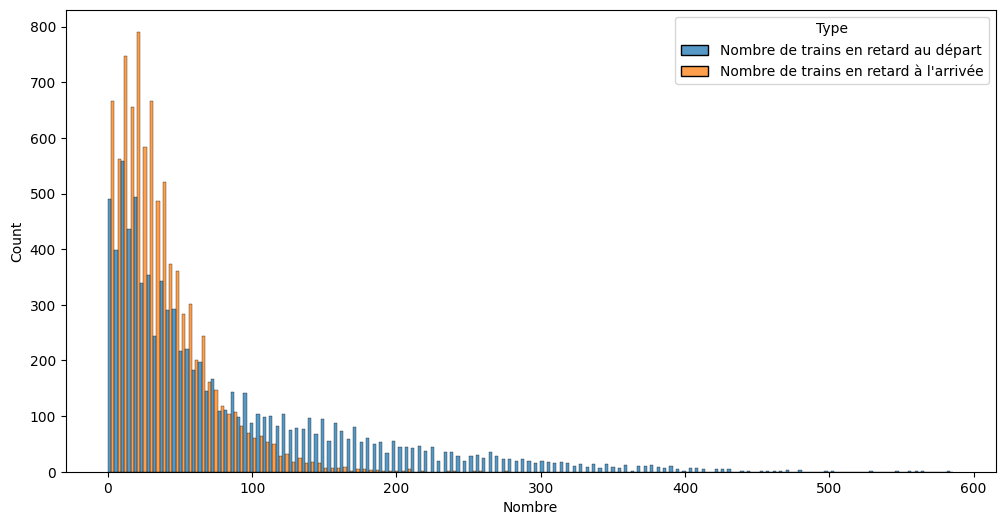

In [25]:
plt.figure(figsize=(12,6))
plot_data = cleaned_data.melt(
    value_vars=[
        "Nombre de trains en retard au départ",
        "Nombre de trains en retard à l'arrivée"
    ],
    var_name="Type",
    value_name="Nombre"
)

# Single histplot with hue
sns.histplot(
    data=plot_data,
    x="Nombre",
    hue="Type",
    multiple="dodge"
)
plt.show()

<Axes: >

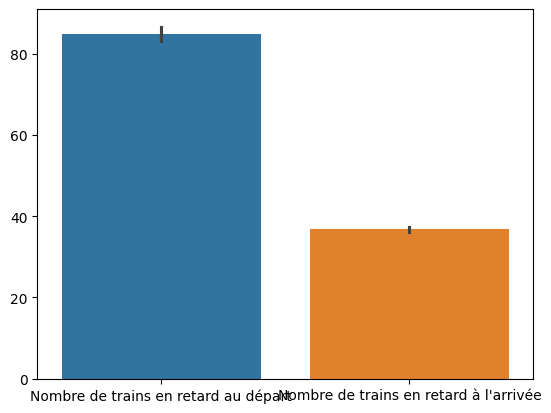

In [26]:
sns.barplot(data = cleaned_data[["Nombre de trains en retard au départ","Nombre de trains en retard à l'arrivée"]] )


In [27]:
total_departure_delays = cleaned_data["Nombre de trains en retard au départ"].sum()
total_arrival_delays = cleaned_data["Nombre de trains en retard à l'arrivée"].sum()
total_trains = cleaned_data["Nombre de circulations prévues"].sum()
total_trains_canceled = cleaned_data["Nombre de trains annulés"].sum()
total_trains_ok = total_trains - total_trains_canceled - total_departure_delays - total_arrival_delays
total_trains_not_ok = total_trains - total_trains_ok
print("Il y a",total_trains_ok,"trains corrects pour",total_trains_not_ok,"trains pas corrects.")
print(round((total_trains_ok / total_trains)*100),"%","des trains performent correctement.")
print(round(((total_arrival_delays + total_departure_delays)/ total_trains)*100),"%","des trains sont en retards.")


mean_delays_departure = cleaned_data['Retard moyen des trains en retard au départ'].mean()
mean_delays_arrival = cleaned_data["Retard moyen des trains en retard à l'arrivée"].mean()
mean_delays_total_departure = cleaned_data['Retard moyen de tous les trains au départ'].mean()
mean_delays_total_arrival = cleaned_data["Retard moyen de tous les trains à l'arrivée"].mean()
print("Moyenne du temps de retard  :",(mean_delays_departure + mean_delays_arrival)/2, "min")
print("Moyenne du temps de retard comprenant les trains arrivés à l'heure:",(mean_delays_total_departure+mean_delays_total_arrival)/2, "min")



Il y a 1230087 trains corrects pour 1125815 trains pas corrects.
52 % des trains performent correctement.
45 % des trains sont en retards.
Moyenne du temps de retard  : 23.87349728981663 min
Moyenne du temps de retard comprenant les trains arrivés à l'heure: 4.806195940491293 min


# Distribution des retards


*on voulais savoir comment était le retard moyen de tout les trains a l'arrivée pour savoir,
si il y avait des donnée "trafiqué" et pour pouvoir avoir une vue general des retard moyen a l'arrivée*


In [19]:
plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.histplot(data=df, x="Retard moyen de tous les trains à l'arrivée", bins=50) # on crée un histogramme en utilisant le dataframe df avec la colonne "Retard moyen de tous les trains à l'arrivée" et en les divisant en 50 intervalles
plt.title("Distribution des retards moyens à l'arrivée") # permet de mettre un titre au graphique
plt.savefig("png/distribution_retards.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques 
plt.close() # permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 



*on a crée une evolution des retards moyen de touts les trains en fonction des mois nous permettant
de voir des pics mais surtout un qui est pour les grandes vacances vraiment gros*

In [20]:

top_stations = df.groupby("Gare de départ")["Retard moyen de tous les trains à l'arrivée"].mean().reset_index() # regroupe les donnée via "gare de départ" et fait calculer la moyenne du retard moyen de chaque gare
top_stations = top_stations.sort_values(by="Retard moyen de tous les trains à l'arrivée", ascending=False).head(10) #trie les gare pour les retard moyen décroissant et fait un top 10 en prenant head les premières, (10) = le nombre de ligne selectionné donc la les 10 premières                

# on a crée une evolution des retards moyen de touts les trains en fonction des mois nous permettant
# de voir des pics mais surtout un qui est pour les grandes vacances vraiment gros
df["Date"] = pd.to_datetime(df["Date"], errors="coerce") # change la colonne en datetime "pour les dates et heures" et pour les erreurs elles sont remplacé en valeur manquantes
df["Month"] = df["Date"].dt.month # crée une nouvelle colonne Month avec dedan extrai le mois de chauqe date


plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.lineplot(data=df, x="Month", y="Retard moyen de tous les trains à l'arrivée", estimator="mean", errorbar=None, marker="o")
plt.title("Évolution du retard moyen par mois") # permet de mettre un titre au graphique
plt.grid(True, linestyle="--", alpha=0.7) # ajout d'une grille sur le graphique linestyle permet de définir le type de ligne pour la grille et alpha gère la transparance
plt.savefig("png/evolution_retard_mois.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 



*graphics sur le top des différentes raison de retard des trains et son pourcentage moyen de chaque cause*

In [21]:

# graphics sur le top des différentes raison de retard des trains et son pourcentage moyen de chaque cause"
causes = [
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
]
mean_causes = df[causes].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6)) # figure creates a new drawing area and figsize changes the size of the drawing
sns.barplot(x=mean_causes.values, y=mean_causes.index)
plt.title("Répartition moyenne des causes de retard") # permet de mettre un titre au graphique
plt.xlabel("Pourcentage moyen")
plt.tight_layout()
plt.savefig("png/causes_retard.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() # permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 

# je voulais tester un top 5 des pires gars d'arrivée au départ de Nantes pour savoir et ducoup voici,
# on peut en deduire grace a ça que probablement des gares comme 
# strasbourg ville ou autres ont été référencer au meme nom : strasbourg, ce qui fait que le graphic 
# est pas très correct

df_nantes = df[df["Gare de départ"].str.contains("NANTES", na=False)]
top_nantes_dest = df_nantes.groupby("Gare d'arrivée")["Retard moyen de tous les trains à l'arrivée"].mean().sort_values(ascending=False).head(5)

plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing  
sns.barplot(x=top_nantes_dest.values, y=top_nantes_dest.index)
plt.title("Top 5 des pires destinations au départ de Nantes") # permet de mettre un titre au graphique
plt.xlabel("Retard moyen à l'arrivée (minutes)")
plt.tight_layout()
plt.savefig("png/nantes_retards.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 

# afin de savoir pourquoi les trains etait en retard au à l'arrivé on a fait une correlation 
# de la moyenne de trajet et du retard moyen des trains en retard a l'arrivée et on peut voir
# que la kde augmente belle est bien et que donc il y a une coréllation"
plt.figure(figsize=(10, 6)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.regplot(
    data=df, 
    x="Durée moyenne du trajet", 
    y="Retard moyen des trains en retard à l'arrivée", 
    scatter_kws={"alpha": 0.3}, 
    line_kws={"color": "red"}
)
plt.title("Corrélation entre la durée du trajet et le retard moyen à l'arrivée") # permet de mettre un titre au graphique
plt.savefig("png/correlation_duree_retard.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 

# afin de savoir pourquoi les trains etait en retard au au départ on a fait une correlation 
# de la moyenne de trajet et du retard moyen des trains en retard a au depart et on peut voir
# que la kde augmente belle est bien et que donc il y a une coréllation"
plt.figure(figsize=(10, 6)) # figure crée une nouvelle zone de dessin et figsize change la taille du dessin 
sns.regplot(
    data=df, 
    x="Durée moyenne du trajet", 
    y="Retard moyen des trains en retard au départ", 
    scatter_kws={"alpha": 0.3}, 
    line_kws={"color": "red"}
)
plt.title("Corrélation entre la durée du trajet et le retard moyen au départ") # permet de mettre un titre au graphique
plt.savefig("png/correlation_duree_retard_depart.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 


plt.figure(figsize=(12, 6)) # figure creates a new drawing area and figsize changes the size of the drawing  
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Carte de chaleur des valeurs manquantes") # permet de mettre un titre au graphique
plt.tight_layout()
plt.savefig("png/valeurs_manquantes.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 


plt.figure(figsize=(10, 2)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.boxplot(data=df, x="Retard moyen de tous les trains à l'arrivée")
plt.title("Détection des valeurs aberrantes (Outliers) - Retard à l'arrivée") # permet de mettre un titre au graphique
plt.tight_layout()
plt.savefig("png/outliers_retard.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 

plt.figure(figsize=(10, 2)) # figure creates a new drawing area and figsize changes the size of the drawing 
sns.boxplot(data=df, x="Durée moyenne du trajet")
plt.title("Détection des valeurs aberrantes (Outliers) - Durée du trajet")
plt.tight_layout()
plt.savefig("png/outliers_duree.png") # permet de sauvegarder et envoyer le fichier png du graphique dans un endroit quelconque en l'occurence la dans notre dossier png avec tout nos graphiques
plt.close() #  permet que le graphique qui devrai apparaître a la suite du code ne s'ouvre pas, de toute facon on en a pas besoin car il est deja envoyé grace au savefig dans le dossier avec nos image png. 


/tmp/ipykernel_92845/453828515.py:70: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
